# Tutorial 2 — Train, Validate, and Understand a Digit CNN

Tutorial 0 introduced tensors and parameter updates. Tutorial 1 followed an image
through convolution, ReLU, pooling, and a classifier. Now we will build real cnn to complete our task.

By the end, you will be able to prepare data, implement training and validation, read learning curves, compare different CNN‘s performance, and save a model you can reuse.

## 0. Background
### 0.1 Epochs, Batches, and Optimizer Steps

| Term | Definition |
|---|---|
| **Epoch** | One pass through the training dataset. An epoch can contain multiple batches. |
| **Batch** | A group of examples processed together in one forward pass. The batch size is the number of examples in that group. |
| **Optimizer step** | One update to the model's trainable parameters using the gradients computed during backpropagation. In a standard training loop, the optimizer takes one step after each batch. |

### Example: Training a CNN on 1,000 images

Suppose we train a CNN to classify images into 10 classes. With a **batch size of 100**, one epoch contains **10 batches**.

1. **Forward pass.** The model processes 100 images together using the same parameters. It outputs logits of shape `[100, 10]`, with one row per image and one score per class.
2. **Batch loss.** We compare each image's scores with its true label and average the 100 individual losses. This average covers **only the images in the current batch**.
3. **Backward pass and update.** We backpropagate through the average loss to compute gradients. One call to `optimizer.step()` uses those gradients to update the model's trainable parameters. The next batch runs with the updated parameters.
4. **End of the epoch.** After all 10 batches, the model has processed all 1,000 images and taken **10 optimizer steps**. We can also report the average loss across all 1,000 images for the epoch.

batch is used to quantify how many steps being updated, epochs are used to quantify how many times the same training data are beeing used. 

Note: the same training data can be used over and over again, as in each round, you can `shuffle=Ture` the training data, then different combination appears in different batches, as model have different weight status, when seeing different input combiniation, will still creating usefull loss and update.

Choosing a batch size
- Smaller batches use less memory and give more updates per epoch. Each update uses fewer examples, so gradients tend to fluctuate more.
- Larger batches usually give smoother gradient estimates and can improve GPU throughput. They use more memory and give fewer updates per epoch. Every image still contributes to the gradient.
- For a small CNN, start with 32 and try 64 or 128. Compare training speed, memory use, and validation accuracy over the same number of epochs.

In our tasks we have 50,000 images and batch size e.g 128, one epoch has 391 batches: 390 full batches and a final batch of 80 images

## 1. Set up one reproducible experiment

Select the project's Python kernel with `torch`, `torchvision`, `numpy`, and
`matplotlib` installed. Run from `number_classifier/` or the repository root.
No GPU is required. The first download needs an internet connection if MNIST is
not already cached.

`QUICK_RUN=False` is the full lesson: 50,000 training and 10,000 validation images,
up to 12 epochs per model, plus a small-data diagnosis experiment. Allow several
minutes on CPU; actual durations are printed. `True` is a short code check using
5,000/2,000 images and three main epochs. 

**Run in order:** select the project's `.venv` kernel, restart it, then choose
**Run All**. Running only the setup cell initializes variables; it does not
start data loading or training. Saved output is not a running Python session.
If this cell prints `Setup complete` but remains busy, restart the kernel;
if VS Code still shows a stale busy indicator, use **Developer: Reload Window**
and select the kernel again. Restarting clears in-memory variables, so run
from the beginning afterward.

In [23]:
from pathlib import Path
from copy import deepcopy
import csv
import json
import random
import time
import os
import platform
import sys

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import torchvision
from IPython.display import Markdown, display

QUICK_RUN = False
config = {
    "profile": "quick" if QUICK_RUN else "full",
    "split_seed": 42, "model_seed": 7, "batch_seed": 123,
    "optimizer": "SGD", "batch_size": 128, "learning_rate": 0.1,
    "max_epochs": 3 if QUICK_RUN else 12,
    "patience": 4, "min_delta": 0.0005,
}
lesson_dir = Path.cwd() if Path("tutorial_1_cnn.ipynb").exists() else Path.cwd() / "number_classifier"
if not (lesson_dir / "tutorial_1_cnn.ipynb").exists():
    raise FileNotFoundError("Run from number_classifier/ or the repository root.")
artifact_dir = lesson_dir / "artifacts" / "tutorial_2" / config["profile"]
artifact_dir.mkdir(parents=True, exist_ok=True)
device = torch.device("cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(config["model_seed"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
TRAIN_COLOR, VAL_COLOR = "#2563a6", "#c06424"
print(f"PyTorch {torch.__version__}; torchvision {torchvision.__version__}; device={device}")
print("Profile:", config["profile"], "| Outputs:", artifact_dir)
print("Notebook Python:", sys.executable, flush=True)
print("Setup complete. Run the next code cell to load MNIST, or use Run All.", flush=True)

PyTorch 2.6.0; torchvision 0.21.0; device=cpu
Profile: full | Outputs: /Users/ctx/Desktop/IC/IC4/Machine Learning for Imaging/mli-tutorials/number_classifier/artifacts/tutorial_2/full
Notebook Python: /Users/ctx/Desktop/IC/IC4/Machine Learning for Imaging/mli-tutorials/.venv/bin/python
Setup complete. Run the next code cell to load MNIST, or use Run All.


## 2. Load data, then decide which examples may teach the model

MNIST contains 28 × 28 grayscale images of digits 0–9. The official training
portion has 60,000 images; the separate test portion has 10,000.

`datasets.MNIST` pairs an image with its integer label. `train=True` selects the
official training portion; it does **not** automatically create our validation
set. `ToTensor()` changes a PIL image into a float tensor with shape `[1, 28, 28]`
and scales its 0–255 pixel values to 0–1.

Loading MNIST from: /Users/ctx/Desktop/IC/IC4/Machine Learning for Imaging/mli-tutorials/data
MNIST loaded.
Official training images: 60000
One input: (1, 28, 28) torch.float32 | range: (0.0, 1.0) | label: 5


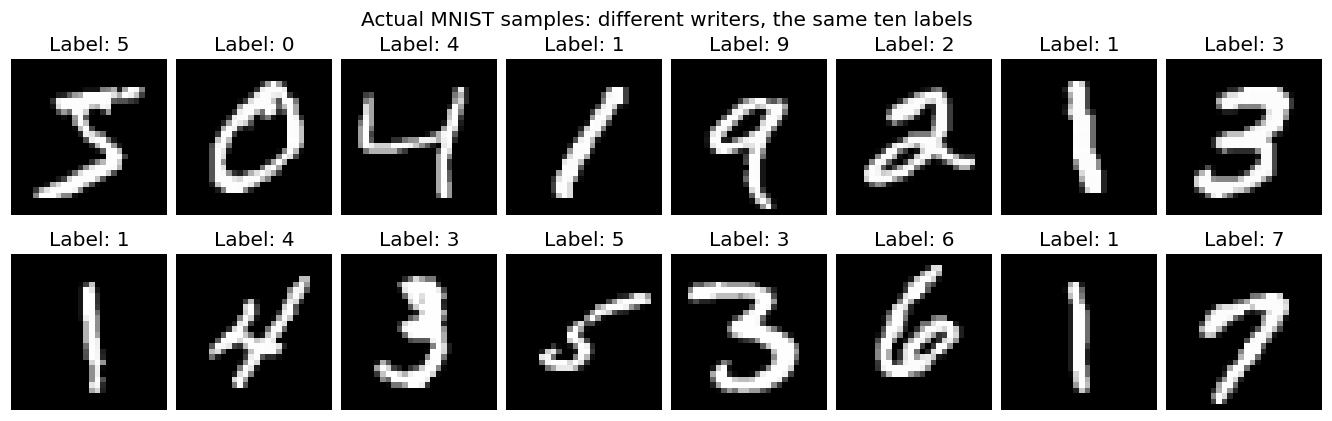

In [24]:
# Reuse the repository's MNIST cache when available.
data_root = lesson_dir.parent / "data"
if not (data_root / "MNIST").exists():
    data_root = lesson_dir / "data"

print("Loading MNIST from:", data_root, flush=True)
mnist = datasets.MNIST(root=data_root, train=True, download=True,
                       transform=transforms.ToTensor())
print("MNIST loaded.", flush=True)
image, label = mnist[0]
print("Official training images:", len(mnist))
print("One input:", tuple(image.shape), image.dtype,
      "| range:", (image.min().item(), image.max().item()), "| label:", label)
assert len(mnist) == 60_000
assert image.shape == (1, 28, 28) and image.dtype == torch.float32
assert 0 <= image.min() <= image.max() <= 1

fig, axes = plt.subplots(2, 8, figsize=(12, 3.8), layout="constrained")
for index, ax in enumerate(axes.flat):
    sample, target = mnist[index]
    ax.imshow(sample[0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {target}")
    ax.axis("off")
fig.suptitle("Actual MNIST samples: different writers, the same ten labels")
plt.show()

### 2.1 Why do we need separate images?

Our goal is **generalization**: making correct predictions on new examples from
the task we care about. A model can learn details specific to its training
examples and fail to generalize. This is **overfitting**.

Imagine revising with a fixed list of handwriting examples. Remembering every
answer on that list does not establish that you can read another person's digits.
We need a separate set to check what transfers.

| Set | Job | Changes weights through gradients? |
| --- | --- | --- |
| Training | Learn parameters from images and labels | Yes |
| Validation | Compare settings and choose a checkpoint | No |
| Test | Evaluate the finalized project on reserved examples | No |

![60,000 official training images become 50,000 training and 10,000 validation images; the official 10,000-image test set remains reserved.](assets/tutorial_2/data_split.png)

The general order would be, you train model for 1 epoch, you validate it through validation set, then you decide whether to do another epochs of training (remember to shuffle data before start of next epoch). You will stop the training when you seeing no imporvement in validation accuracy. or imporving training accuracy but degredation on validation accuracy(overfitting).

Note there is in total 7000 samples, 6000 training data are split into validation set and training set. the last 1000 test set are isolate until finished training.

If later adding data augmentation, split the original images first and augment
only training examples. 

In [25]:
split_generator = torch.Generator().manual_seed(config["split_seed"])
permutation = torch.randperm(len(mnist), generator=split_generator)
full_train_indices = permutation[:50_000].tolist()
full_val_indices = permutation[50_000:].tolist()
assert set(full_train_indices).isdisjoint(full_val_indices)
assert len(set(full_train_indices + full_val_indices)) == len(mnist)

train_indices = full_train_indices[:5_000] if QUICK_RUN else full_train_indices
val_indices = full_val_indices[:2_000] if QUICK_RUN else full_val_indices
train_set = Subset(mnist, train_indices)
val_set = Subset(mnist, val_indices)
split_record = {
    "source": "MNIST official training portion", "seed": config["split_seed"],
    "full_train_indices": full_train_indices, "full_val_indices": full_val_indices,
    "used_train_indices": train_indices, "used_val_indices": val_indices,
}
(artifact_dir / "split.json").write_text(json.dumps(split_record), encoding="utf-8")
print(f"Used for training: {len(train_set):,}; validation: {len(val_set):,}")
print("Official test set: reserved; no test dataset was created.")

Used for training: 50,000; validation: 10,000
Official test set: reserved; no test dataset was created.


`Subset` stores selected indices into a dataset. Both subsets can refer to the
same MNIST object because their indices are disjoint. This lesson records its own
50,000/10,000 split in `artifacts/tutorial_2/<profile>/split.json`; it does not reuse
or overwrite older Tutorial 1 preview splits or checkpoints.

Before training, check whether every digit is represented. A **class** is one
possible label, here a digit from 0 to 9. Random splitting does not give exactly
equal counts, but this large split should include many examples of each class.
The plot compares proportions because the two sets have different sizes.

Digit:      [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Train:      [4923, 5613, 4958, 5093, 4863, 4546, 4933, 5204, 4882, 4985]
Validation: [1000, 1129, 1000, 1038, 979, 875, 985, 1061, 969, 964]


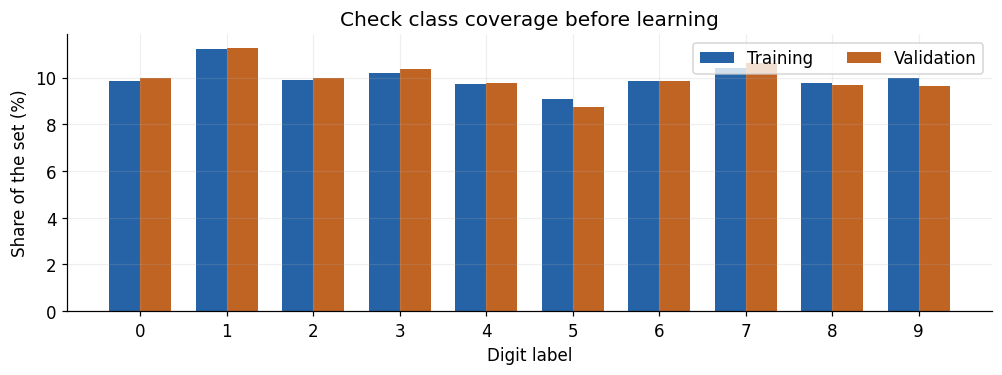

In [26]:
train_counts = torch.bincount(mnist.targets[train_indices], minlength=10)
val_counts = torch.bincount(mnist.targets[val_indices], minlength=10)
assert (train_counts > 0).all() and (val_counts > 0).all()
print("Digit:     ", list(range(10)))
print("Train:     ", train_counts.tolist())
print("Validation:", val_counts.tolist())
fig, ax = plt.subplots(figsize=(9, 3.3), layout="constrained")
digits = np.arange(10)
ax.bar(digits - .18, 100 * train_counts.numpy() / len(train_set), .36,
       label="Training", color=TRAIN_COLOR)
ax.bar(digits + .18, 100 * val_counts.numpy() / len(val_set), .36,
       label="Validation", color=VAL_COLOR)
ax.set(xticks=digits, xlabel="Digit label", ylabel="Share of the set (%)",
       title="Check class coverage before learning")
ax.legend(ncol=2)
plt.show()

## 3. Turn each set into batches


`DataLoader` groups the pairs into inputs `[B, 1, 28, 28]` and labels `[B]`.
Training uses `shuffle=True` to vary the order in each batch， e.g different label‘s data can be mixed in one batch.
Evaluation uses`shuffle=False` so predictions stay aligned with dataset indices. We use `num_workers=0` for a simple, portable notebook.

We use a separate loader to **evaluate training data without updates**. That will
let us compare training and validation at exactly the same model weights.

In [27]:
def make_train_loader(dataset, batch_seed, batch_size=128):
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      generator=torch.Generator().manual_seed(batch_seed))

def make_eval_loader(dataset):
    """evaluate loss after each epoch"""
    return DataLoader(dataset, batch_size=256, shuffle=False, num_workers=0)

train_eval_loader = make_eval_loader(train_set)
val_loader = make_eval_loader(val_set)
# This preview loader is separate from the loaders used by the actual experiments.
preview_loader = make_train_loader(train_set, config["batch_seed"], config["batch_size"])
batch_images, batch_labels = next(iter(preview_loader))
print("Input batch:", tuple(batch_images.shape), batch_images.dtype)
print("Label batch:", tuple(batch_labels.shape), batch_labels.dtype)
print("Updates per full epoch:", len(preview_loader))
assert batch_labels.dtype == torch.long
assert batch_images.shape[0] == batch_labels.shape[0]

Input batch: (128, 1, 28, 28) torch.float32
Label batch: (128,) torch.int64
Updates per full epoch: 391


**Check your understanding.** If you double the batch size, do you double the
number of distinct training images? Does shuffling move validation images into
training?

<details><summary>Reasoning guide</summary>

No. Batch size changes how many examples are used in one update and how many
updates make an epoch. The dataset membership stays the same. The loader only
shuffles the subset it receives; it cannot move validation indices into training.

</details>

## 4. Choose two small CNNs

Start with a model we can explain and train quickly. Model A uses one
**convolution → ReLU → pooling** block. Model B uses two blocks with more channels.
Tutorial 1 ended with two blocks of 4 and 8 channels; A is a deliberately simpler
baseline, while B tests more feature capacity using the same building blocks.

**Why 3 × 3 kernels?** They provide a small, economical local window for stroke
patterns. A second convolution combines earlier responses over a larger region
of the original image. More channels allow more learned feature maps. Neither
extra depth nor width guarantees better validation performance.

With stride 1 and padding 1, each convolution preserves height and width. A
2 × 2, stride-2 pool halves them. We begin here rather than searching many kernel
sizes: first establish whether this simple choice works.

![Model A has one block with four channels; model B has two blocks with 16 and 32 channels. Both end in ten logits.](assets/tutorial_2/cnn_comparison.png)

| Property | A: TinyDigitCNN | B: WiderDigitCNN |
| --- | --- | --- |
| Convolution channels | 1 → 4 | 1 → 16 → 32 |
| Feature maps before flatten | 4 × 14 × 14 | 32 × 7 × 7 |
| Linear classifier | 784 → 10 | 1,568 → 10 |
| Learnable parameters, including biases | 7,890 | 20,490 |

Both outputs are **logits**: ten raw scores per image. We do not add Softmax inside
these models. There is no Dropout, augmentation in this first
comparison, so we can focus on architecture. 

In [28]:
class TinyDigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(nn.Flatten(start_dim=1), nn.Linear(4 * 14 * 14, 10))

    def forward(self, images):
        return self.classifier(self.features(images))


class WiderDigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(nn.Flatten(start_dim=1), nn.Linear(32 * 7 * 7, 10))

    def forward(self, images):
        return self.classifier(self.features(images))

model_classes = {"A": TinyDigitCNN, "B": WiderDigitCNN}

### 4.1 Check shapes before spending time on training

Send two images through each layer. `B` in a shape means batch size, not model B.
The final shape must be `[2, 10]`: one row of ten scores for each image.
`parameter.numel()` counts entries in a parameter tensor; summing it over the
model gives the total learned weights and biases.

In [29]:
with torch.no_grad():
    for name, constructor in model_classes.items():
        probe = constructor()
        values = batch_images[:2]
        print(f"\nModel {name}: input {tuple(values.shape)}")
        for layer in list(probe.features) + list(probe.classifier):
            values = layer(values)
            print(f"  {type(layer).__name__:12s} → {tuple(values.shape)}")
        parameter_count = sum(p.numel() for p in probe.parameters())
        print("  Learnable parameters:", parameter_count)
        assert values.shape == (2, 10)
        assert parameter_count == {"A": 7890, "B": 20490}[name]


Model A: input (2, 1, 28, 28)
  Conv2d       → (2, 4, 28, 28)
  ReLU         → (2, 4, 28, 28)
  MaxPool2d    → (2, 4, 14, 14)
  Flatten      → (2, 784)
  Linear       → (2, 10)
  Learnable parameters: 7890

Model B: input (2, 1, 28, 28)
  Conv2d       → (2, 16, 28, 28)
  ReLU         → (2, 16, 28, 28)
  MaxPool2d    → (2, 16, 14, 14)
  Conv2d       → (2, 32, 14, 14)
  ReLU         → (2, 32, 14, 14)
  MaxPool2d    → (2, 32, 7, 7)
  Flatten      → (2, 1568)
  Linear       → (2, 10)
  Learnable parameters: 20490


## 5. Measure a prediction, then make one update

### 5.1 Cross-entropy and accuracy answer different questions

Tutorial 1 used squared error to make forward and backward calculations concrete.
Here we use **cross-entropy**, as introduced in Tutorial 0, for ten-class
classification. For one image with correct label $y$:

$$L=-\log p_y,$$

where $p_y$ is the probability assigned to its correct class. If that probability
is 0.1, the loss is about 2.303; at 0.9 it is about 0.105. The natural logarithm
makes confidently wrong predictions especially costly. 

`nn.CrossEntropyLoss()` takes **raw logits** and integer labels. It handles the
log-probability calculation internally. Softmax is useful for *displaying*
probabilities, but should not be applied before this loss.

**Accuracy** only asks whether the highest-scoring class is correct. 

### 5.2 Separate gradient calculation from the parameter update

We use ordinary **SGD**, following the gradient-descent rule from Tutorials 0–1:

**new parameter = old parameter − learning rate × gradient**

Here the gradient comes from the batch's mean loss, and the learning rate is
`0.1`. `backward()` calculates gradients; `optimizer.step()` applies the update.
The learning rate stays fixed throughout each run. Both models use the same
setting so we can focus on the training workflow and compare their structures.

| Line | Effect |
| --- | --- |
| `model.train()` | Select training behavior |
| `optimizer.zero_grad()` | Clear gradients left from an earlier update |
| `logits = model(images)` | Calculate predictions using current parameters |
| `loss_fn(logits, labels)` | Measure the prediction error |
| `loss.backward()` | Calculate parameter gradients |
| `optimizer.step()` | Update parameters using those gradients |

The demonstration below uses a separate model. Actual experiments will start
from fresh models and optimizers.

In [30]:
loss_fn = nn.CrossEntropyLoss()

seed_everything(config["model_seed"])
demo_model = TinyDigitCNN().to(device)
demo_optimizer = torch.optim.SGD(demo_model.parameters(), lr=config["learning_rate"])
images, labels = batch_images.to(device), batch_labels.to(device)
weights_before = demo_model.features[0].weight.detach().clone()

demo_model.train()
demo_optimizer.zero_grad()
logits = demo_model(images)
loss = loss_fn(logits, labels)
loss.backward()
print("First convolution's gradient norm:", demo_model.features[0].weight.grad.norm().item())
demo_optimizer.step()
with torch.no_grad():
    loss_after = loss_fn(demo_model(images), labels).item()
print(f"Same batch: before={loss.item():.4f}, after={loss_after:.4f}")
print("Weights changed:", not torch.equal(weights_before, demo_model.features[0].weight))
assert not torch.equal(weights_before, demo_model.features[0].weight)

First convolution's gradient norm: 0.07501779496669769
Same batch: before=2.3162, after=2.2618
Weights changed: True


## 6. Write training and evaluation as separate functions

### 6.1 Give every image equal weight in the epoch report

The loss function returns a batch mean. Multiplying by the batch size recovers
its summed loss; add these sums and divide by the total number of examples:

$$L_{\mathrm{epoch}}=\frac{\sum_b n_b L_b}{\sum_b n_b}.$$

For batches of 128 and 80 images with mean losses 0.2 and 0.5, the combined mean
is $(128\times0.2+80\times0.5)/208\approx0.315$, not $(0.2+0.5)/2=0.35$.
This matters for the last short batch.


In [31]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    loss_sum, correct, seen = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        if not torch.isfinite(loss):
            raise ValueError("Non-finite loss: inspect inputs, gradients, and learning rate.")
        loss.backward()
        optimizer.step()
        count = labels.shape[0]
        loss_sum += loss.item() * count
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += count
    return {"loss": loss_sum / seen, "accuracy": correct / seen, "n": seen}

### 6.2 Evaluate without changing the model
#### 6.2.1 difference between `.eval()` `.train()` and `.no_grad()`
`model.eval()` selects evaluation behavior; `torch.no_grad()` disables gradient
tracking. They have different jobs. Our current layers behave identically in
training and evaluation modes, but future, some layers have different behavior in differnt mode, such as Dropout or BatchNorm layers, will talk that in next tutorial.

Evaluation still uses labels to compute metrics. It has **no backward call and
no optimizer step**. The training loop must switch back with `model.train()` on
the next epoch. 

Reference: [PyTorch training and evaluation](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html).

In [32]:
def evaluate(model, loader, collect_predictions=False):
    model.eval()
    loss_sum, correct, seen = 0.0, 0, 0
    targets, predictions, confidences = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = loss_fn(logits, labels)
            predicted = logits.argmax(dim=1)
            count = labels.shape[0]
            loss_sum += loss.item() * count
            correct += (predicted == labels).sum().item()
            seen += count
            if collect_predictions:
                targets.append(labels.cpu())
                predictions.append(predicted.cpu())
                confidences.append(logits.softmax(dim=1).max(dim=1).values.cpu())
    metrics = {"loss": loss_sum / seen, "accuracy": correct / seen, "n": seen}
    if collect_predictions:
        metrics.update(targets=torch.cat(targets), predictions=torch.cat(predictions),
                       confidences=torch.cat(confidences))
    return metrics

**A useful check before a long run:** evaluating a small sample should leave
every learned tensor unchanged. Passing this check does not establish accuracy;
it checks that measurement is not secretly training the model.

In [33]:
state_before = deepcopy(demo_model.state_dict())
small_check = make_eval_loader(Subset(val_set, range(32)))
check_metrics = evaluate(demo_model, small_check)
assert check_metrics["n"] == 32
assert all(torch.equal(value, demo_model.state_dict()[key])
           for key, value in state_before.items())
print("Evaluation left all learned tensors unchanged.")

Evaluation left all learned tensors unchanged.


## 7. Train, validate every epoch, and keep the best checkpoint

![One epoch trains on batches, evaluates both sets at the current weights, records metrics, and decides whether to continue.](assets/tutorial_2/epoch_workflow.png)

**Read the diagram:** validation is part of the repeated workflow. Waiting until
the very end would hide when performance was best and when it began to worsen.

A **checkpoint** records a model's state at a particular moment. We select the
checkpoint with the **lowest validation cross-entropy**, a rule chosen before
looking at the results. The last epoch is not necessarily the best epoch.

**Early stopping** ends training after improvement has stalled. Here, `patience=4`
means stop after four consecutive epochs without an improvement exceeding
`min_delta=0.0005` relative to the last significant improvement.
This tolerance is an experiment setting, not a universal overfitting threshold.

`deepcopy(model.state_dict())` makes an independent snapshot. Plain assignment
would keep references that subsequent updates can change. At the end we restore
the snapshot, save it, and return both the model and its full learning history.
An epoch-0 measurement records the untrained model before any updates.

### 7.1 What is inside `state_dict()`, and what does `deepcopy` copy?

`model.state_dict()` maps **names to tensors**. In our CNN, these are the
convolutional and linear **weights and biases**. For example,
`features.0.weight` is the first convolution's weight tensor, with shape
`[4, 1, 3, 3]` in model A. ReLU, pooling, and flattening contribute no entries
because they have no stored tensor state. Other layers can also store
**persistent buffers**, such as BatchNorm's running statistics.

This dictionary does not contain the model's Python architecture, gradients,
optimizer state, or training history. We inspect a copy of the earlier demo
model below. The output shows every key and shape, followed by the actual
tensors; PyTorch abbreviates large tensors with `...`.

In [34]:
# Use a separate model for inspection; the training experiments start fresh.
state_demo_model = deepcopy(demo_model)
live_state = state_demo_model.state_dict()
for name, tensor in live_state.items():
    print(f"{name:24s} shape={tuple(tensor.shape)}, dtype={tensor.dtype}")
print("\nActual state_dict (large tensors are abbreviated):")
print(live_state)

features.0.weight        shape=(4, 1, 3, 3), dtype=torch.float32
features.0.bias          shape=(4,), dtype=torch.float32
classifier.1.weight      shape=(10, 784), dtype=torch.float32
classifier.1.bias        shape=(10,), dtype=torch.float32

Actual state_dict (large tensors are abbreviated):
OrderedDict({'features.0.weight': tensor([[[[ 0.0233, -0.2008,  0.1061],
          [ 0.1046, -0.1782, -0.0500],
          [-0.1953,  0.0865, -0.0898]]],


        [[[ 0.2333,  0.2353,  0.0327],
          [-0.1425, -0.1963, -0.0367],
          [-0.0939,  0.1468, -0.2846]]],


        [[[ 0.3101, -0.2642,  0.2531],
          [-0.0597,  0.1697,  0.1285],
          [ 0.0137,  0.0623,  0.2534]]],


        [[[ 0.0846,  0.1748, -0.2600],
          [ 0.2362,  0.1134,  0.0828],
          [ 0.0447,  0.1610,  0.3047]]]]), 'features.0.bias': tensor([-0.0742, -0.1866, -0.0852, -0.2050]), 'classifier.1.weight': tensor([[ 0.0172, -0.0177, -0.0191,  ...,  0.0210, -0.0062,  0.0291],
        [-0.0133, -0.0010,  0.

`state_dict()` creates a dictionary whose tensors **share storage with the
model**. Saving that dictionary in a variable, or making a shallow dictionary
copy, does not freeze the numbers. `deepcopy(model.state_dict())` copies the
dictionary and its tensor data into an independent in-memory snapshot.

In this small demonstration, increase one bias by 1 on the inspection model.
The live dictionary follows the change, but the deep copy keeps the earlier
value. `load_state_dict(snapshot)` then restores the snapshot into the same
architecture. `deepcopy` itself does not write a file; `torch.save` does that
later. This is why `fit` uses a deep copy when it finds a better checkpoint.

Reference: [PyTorch model state and checkpoint snapshots](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).

In [35]:
snapshot = deepcopy(live_state)
key = "features.0.bias"
print("Before change:", live_state[key][0].item())
with torch.no_grad():
    state_demo_model.features[0].bias[0].add_(1.0)
print("Model now:    ", state_demo_model.features[0].bias[0].item())
print("Live dict:    ", live_state[key][0].item())
print("Deep copy:    ", snapshot[key][0].item())
assert live_state[key].data_ptr() == state_demo_model.features[0].bias.data_ptr()
assert snapshot[key].data_ptr() != live_state[key].data_ptr()
torch.testing.assert_close(live_state[key][0], snapshot[key][0] + 1)

state_demo_model.load_state_dict(snapshot)
assert all(torch.equal(value, state_demo_model.state_dict()[name])
           for name, value in snapshot.items())
print("Restored bias: ", state_demo_model.features[0].bias[0].item())

Before change: -0.0741657093167305
Model now:     0.9258342981338501
Live dict:     0.9258342981338501
Deep copy:     -0.0741657093167305
Restored bias:  -0.0741657093167305


### 7.2 Put checkpoint selection into the training loop

In [36]:
def fit(model, train_loader, train_measure_loader, validation_loader, name,
        max_epochs, learning_rate, patience=4, min_delta=0.0005, log_every=1):
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    print(f"{name}: measuring the untrained model before epoch 1...", flush=True)
    initial_train = evaluate(model, train_measure_loader)
    initial_val = evaluate(model, validation_loader)
    history = [{"epoch": 0, "online_train_loss": None,
                "train_loss": initial_train["loss"], "train_accuracy": initial_train["accuracy"],
                "val_loss": initial_val["loss"], "val_accuracy": initial_val["accuracy"],
                "seconds": 0.0}]
    best_loss, best_epoch = initial_val["loss"], 0
    best_state = deepcopy(model.state_dict())
    significant_best, stale_epochs = best_loss, 0
    started = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        epoch_started = time.perf_counter()
        online = train_one_epoch(model, train_loader, optimizer)
        train_metrics = evaluate(model, train_measure_loader)
        val_metrics = evaluate(model, validation_loader)
        history.append({"epoch": epoch, "online_train_loss": online["loss"],
                        "train_loss": train_metrics["loss"], "train_accuracy": train_metrics["accuracy"],
                        "val_loss": val_metrics["loss"], "val_accuracy": val_metrics["accuracy"],
                        "seconds": time.perf_counter() - epoch_started})
        if val_metrics["loss"] < best_loss:
            best_loss, best_epoch = val_metrics["loss"], epoch
            best_state = deepcopy(model.state_dict())
        if val_metrics["loss"] < significant_best - min_delta:
            significant_best, stale_epochs = val_metrics["loss"], 0
        else:
            stale_epochs += 1
        if epoch == 1 or epoch % log_every == 0 or epoch == max_epochs:
            print(f"{name} | {epoch:02d}/{max_epochs} | train CE={train_metrics['loss']:.4f} | "
                  f"val CE={val_metrics['loss']:.4f} | val acc={val_metrics['accuracy']:.2%} | "
                  f"{history[-1]['seconds']:.1f}s", flush=True)
        if patience is not None and stale_epochs >= patience:
            print(f"Early stopping at epoch {epoch}; restoring epoch {best_epoch}.")
            break

    elapsed = time.perf_counter() - started
    model.load_state_dict(best_state)
    model.eval()
    checkpoint_path = artifact_dir / f"{name}_best.pt"
    torch.save({"state_dict": best_state, "architecture": type(model).__name__,
                "best_epoch": best_epoch, "best_val_loss": best_loss,
                "optimizer": "SGD", "learning_rate": learning_rate,
                "preprocessing": "ToTensor: grayscale 1x28x28, pixels in [0,1]"}, checkpoint_path)
    (artifact_dir / f"{name}_history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
    print(f"{name}: selected epoch {best_epoch}, validation CE={best_loss:.4f}, elapsed={elapsed:.1f}s")
    return {"model": model, "history": history, "best_epoch": best_epoch,
            "seconds": elapsed, "checkpoint": checkpoint_path,
            "parameters": sum(p.numel() for p in model.parameters())}

### 7.3 Run a fair first comparison

Both models use the same images, preprocessing, batch order, plain SGD with learning rate 0.1,
maximum epochs, stopping rule, and checkpoint rule. A fresh loader resets the
batch generator for each run. Each run constructs a fresh model and its own optimizer, so neither model
starts from the other model's learned weights.

The models have different parameter shapes, so a shared seed does not give them
identical starting weights. 
The curves will compare **end-of-epoch training and validation measurements**,
both with fixed weights and without augmentation. Rerunning this cell retrains
from scratch and replaces this profile's A/B checkpoints and history files.

In [37]:
results = {}
for name, constructor in model_classes.items():
    seed_everything(config["model_seed"])
    model = constructor().to(device)
    loader = make_train_loader(train_set, config["batch_seed"], config["batch_size"])
    results[name] = fit(
        model, loader, train_eval_loader, val_loader, name,
        max_epochs=config["max_epochs"], learning_rate=config["learning_rate"],
        patience=config["patience"], min_delta=config["min_delta"],
    )

A: measuring the untrained model before epoch 1...
A | 01/12 | train CE=0.3695 | val CE=0.3795 | val acc=88.25% | 6.1s
A | 02/12 | train CE=0.2798 | val CE=0.2941 | val acc=91.37% | 6.7s
A | 03/12 | train CE=0.2123 | val CE=0.2270 | val acc=93.48% | 6.4s
A | 04/12 | train CE=0.1734 | val CE=0.1919 | val acc=94.69% | 7.3s
A | 05/12 | train CE=0.1611 | val CE=0.1778 | val acc=95.01% | 6.1s
A | 06/12 | train CE=0.1369 | val CE=0.1536 | val acc=95.89% | 6.2s
A | 07/12 | train CE=0.1230 | val CE=0.1425 | val acc=96.10% | 8.1s
A | 08/12 | train CE=0.1120 | val CE=0.1310 | val acc=96.50% | 7.3s
A | 09/12 | train CE=0.1088 | val CE=0.1302 | val acc=96.18% | 8.1s
A | 10/12 | train CE=0.1015 | val CE=0.1214 | val acc=96.67% | 8.2s
A | 11/12 | train CE=0.0942 | val CE=0.1165 | val acc=96.77% | 6.8s
A | 12/12 | train CE=0.0889 | val CE=0.1124 | val acc=96.93% | 7.1s
A: selected epoch 12, validation CE=0.1124, elapsed=84.3s
B: measuring the untrained model before epoch 1...
B | 01/12 | train CE=0.1

## 8. Read the loss curves before changing the model

### 8.1 Did learning slow down? Did the two sets move together?

In each panel, blue is training loss and orange is validation loss. Epoch 0 is
the untrained model. The vertical line marks the selected checkpoint, not an
assumed point where training must stop improving. The plotted training loss is
measured after each epoch, not the changing-weight average from the update loop.

Observe the initial drop, the later slope, and whether the two curves separate.
Both models use the same vertical scale in this overview. The following plots
then magnify the later behavior without removing the full context.

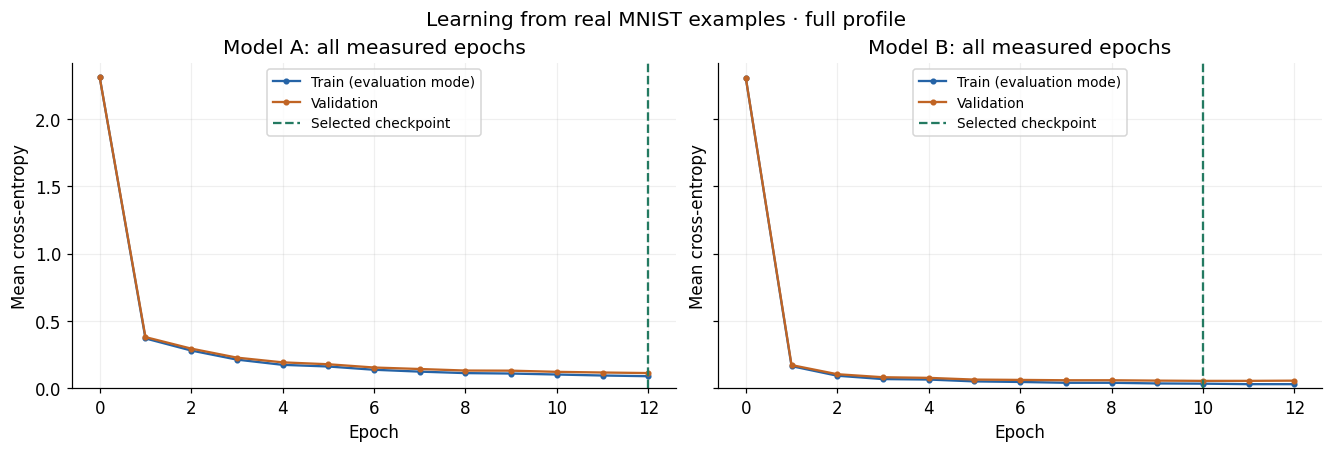

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout="constrained")
for ax, (name, result) in zip(axes, results.items()):
    history = result["history"]
    epochs = [row["epoch"] for row in history]
    ax.plot(epochs, [row["train_loss"] for row in history], "o-", ms=3,
            color=TRAIN_COLOR, label="Train (evaluation mode)")
    ax.plot(epochs, [row["val_loss"] for row in history], "o-", ms=3,
            color=VAL_COLOR, label="Validation")
    ax.axvline(result["best_epoch"], color="#237a61", ls="--", label="Selected checkpoint")
    ax.set(title=f"Model {name}: all measured epochs", xlabel="Epoch", ylabel="Mean cross-entropy")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=9)
fig.suptitle(f"Learning from real MNIST examples · {config['profile']} profile")
fig.savefig(artifact_dir / "learning_curves.png", dpi=180, bbox_inches="tight")
plt.show()

### 8.2 Use the pattern to choose the next experiment

| Observed pattern over several epochs | Possible interpretation | Next useful check |
| --- | --- | --- |
| Both losses still fall | Learning is continuing | Allow more training within a recorded budget |
| Both stay high and nearly flat | Underfitting or an optimization/implementation problem | Check inputs, gradients, learning rate; then capacity |
| Loss jumps or becomes non-finite | Updates may be too large or numerically unstable | Inspect data and gradients; reduce learning rate |
| Train loss falls while validation loss rises | Evidence of overfitting | Restore the best checkpoint; investigate regularization or data |
| Both are low and stable | Good performance for this split and setup | Inspect remaining mistakes and cost |

**Underfitting** means the model has not captured enough of the training task.
It can arise from limited capacity or insufficient/effectively poor training.
**Convergence** here means the measured optimization progress has become small;
it does not prove that we found the best possible model.

## 9. Compare the selected models, not just their last epochs

An accuracy increase and an error-rate reduction use different denominators:

$$\text{error rate}=1-\text{accuracy},\qquad
\text{relative error reduction}=\frac{e_A-e_B}{e_A}\times100\%.$$

For example, 98% → 98.2% accuracy is **+0.2 percentage points**, while the error
rate 2% → 1.8% is a **10% relative reduction**. This is an illustrative example.
Our experimental aim is to see whether B reduces validation error by about 10%
or more. 
Each model below has already been restored to its lowest-validation-loss
checkpoint.

In [42]:
comparison = []
for name, result in results.items():
    train_metrics = evaluate(result["model"], train_eval_loader)
    val_metrics = evaluate(result["model"], val_loader)
    result["train_metrics"], result["val_metrics"] = train_metrics, val_metrics
    comparison.append({"model": name, "parameters": result["parameters"],
                       "trained_epochs": len(result["history"]) - 1,
                       "best_epoch": result["best_epoch"], "train_loss": train_metrics["loss"],
                       "val_loss": val_metrics["loss"], "train_accuracy": train_metrics["accuracy"],
                       "val_accuracy": val_metrics["accuracy"], "seconds": result["seconds"]})

table = "| Model | Params | Epochs run / selected | Train CE | Val CE | Train acc. | Val acc. | Time (s) |\n"
table += "| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |\n"
for row in comparison:
    table += (f"| {row['model']} | {row['parameters']:,} | {row['trained_epochs']} / {row['best_epoch']} "
              f"| {row['train_loss']:.4f} | {row['val_loss']:.4f} | {row['train_accuracy']:.2%} "
              f"| {row['val_accuracy']:.2%} | {row['seconds']:.1f} |\n")
display(Markdown(table))
error_a = 1 - results["A"]["val_metrics"]["accuracy"]
error_b = 1 - results["B"]["val_metrics"]["accuracy"]
relative_error_reduction = (error_a - error_b) / error_a if error_a > 0 else None
print(f"Accuracy change B − A: {(error_a - error_b) * 100:+.2f} percentage points")
if relative_error_reduction is None:
    print("Relative error reduction is undefined because A made no validation errors.")
else:
    print(f"Relative error reduction: {relative_error_reduction:.1%}")
    print("At least 10% reduction observed:", relative_error_reduction >= 0.10)

selected_name = min(results, key=lambda name: results[name]["val_metrics"]["loss"])
selected_model = results[selected_name]["model"]
print("Model selected by validation cross-entropy:", selected_name)

| Model | Params | Epochs run / selected | Train CE | Val CE | Train acc. | Val acc. | Time (s) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| A | 7,890 | 12 / 12 | 0.0889 | 0.1124 | 97.46% | 96.93% | 84.3 |
| B | 20,490 | 12 / 10 | 0.0335 | 0.0543 | 98.98% | 98.47% | 198.7 |


Accuracy change B − A: +1.54 percentage points
Relative error reduction: 50.2%
At least 10% reduction observed: True
Model selected by validation cross-entropy: B


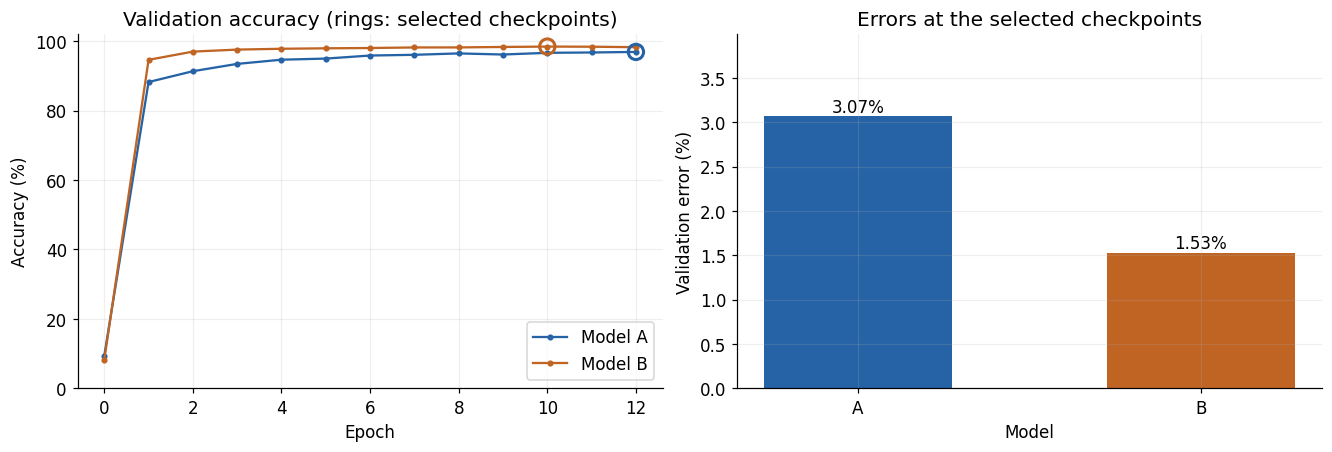

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for name, color in [("A", TRAIN_COLOR), ("B", VAL_COLOR)]:
    result = results[name]
    history = result["history"]
    epochs = [row["epoch"] for row in history]
    axes[0].plot(epochs, [100 * row["val_accuracy"] for row in history], "o-", ms=3,
                 label=f"Model {name}", color=color)
    chosen = history[result["best_epoch"]]
    axes[0].scatter(chosen["epoch"], 100 * chosen["val_accuracy"], s=100,
                    facecolors="none", edgecolors=color, linewidths=2, zorder=4)
    error_percent = 100 * (1 - result["val_metrics"]["accuracy"])
    axes[1].bar(name, error_percent, color=color, width=.55)
    axes[1].text(name, error_percent, f"{error_percent:.2f}%", ha="center", va="bottom")
axes[0].set(title="Validation accuracy (rings: selected checkpoints)",
            xlabel="Epoch", ylabel="Accuracy (%)", ylim=(0, 102))
axes[0].legend()
axes[1].set(title="Errors at the selected checkpoints", xlabel="Model", ylabel="Validation error (%)")
axes[1].set_ylim(0, max(100 * error_a, 100 * error_b, .1) * 1.3)
fig.savefig(artifact_dir / "model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. What if the digit rotates, changes size, or moves?

Our validation score describes the original MNIST images. A person using a
drawing canvas might write a tilted digit, draw it smaller, or place it away
from the center. **Will the same trained model still recognize it?**

We will create transformed copies of the validation images and evaluate the
already selected model. This measures **robustness**: how well its predictions
hold up under specified changes to the input.

### 10.1 Change one property at a time

| Condition | Change to each validation image |
| --- | --- |
| Original | No change; our reference score |
| Rotate −30°, −15°, +15°, +30° | Rotate about the image center; positive angles are clockwise here |
| Scale ×0.8 or ×1.2 | Shrink or enlarge the digit about the center |
| Shift right 4 px or down 4 px | Move the digit by four pixels in one direction |

Every result stays **1 × 28 × 28**, with black background and values in [0, 1].
The label stays the same. These are fixed conditions, chosen before measuring
their results, and every condition uses the same validation indices in the
same order. Full mode evaluates all 10,000 images per condition; quick mode
uses its 2,000 validation images.

In [49]:
from torch.utils.data import Dataset
from torchvision.transforms import functional as TF, InterpolationMode

# (name, angle in degrees, size multiplier, (horizontal shift, vertical shift))
robustness_conditions = [
    ("Original", 0, 1.0, (0, 0)),
    ("Rotate -30°", -30, 1.0, (0, 0)),
    ("Rotate -15°", -15, 1.0, (0, 0)),
    ("Rotate +15°", 15, 1.0, (0, 0)),
    ("Rotate +30°", 30, 1.0, (0, 0)),
    ("Scale ×0.8", 0, 0.8, (0, 0)),
    ("Scale ×1.2", 0, 1.2, (0, 0)),
    ("Right 4 px", 0, 1.0, (4, 0)),
    ("Down 4 px", 0, 1.0, (0, 4)),
]

def transform_digit(image, condition):
    _, angle, scale, shift = condition
    if angle == 0 and scale == 1.0 and shift == (0, 0):
        return image
    return TF.affine(image, angle=angle, translate=list(shift), scale=scale,
                     shear=0, interpolation=InterpolationMode.BILINEAR, fill=0)


class TransformedValidation(Dataset):
    def __init__(self, base_dataset, condition):
        self.base_dataset = base_dataset
        self.condition = condition

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image, label = self.base_dataset[index]
        return transform_digit(image, self.condition), label

The preview uses the first validation example of digits 2 and 5, selected by
label before looking at transformed predictions. Each row starts from exactly
the same image. Compare the tilt, digit size, position, and any lost border
strokes; we are changing the input, not the label or the model.

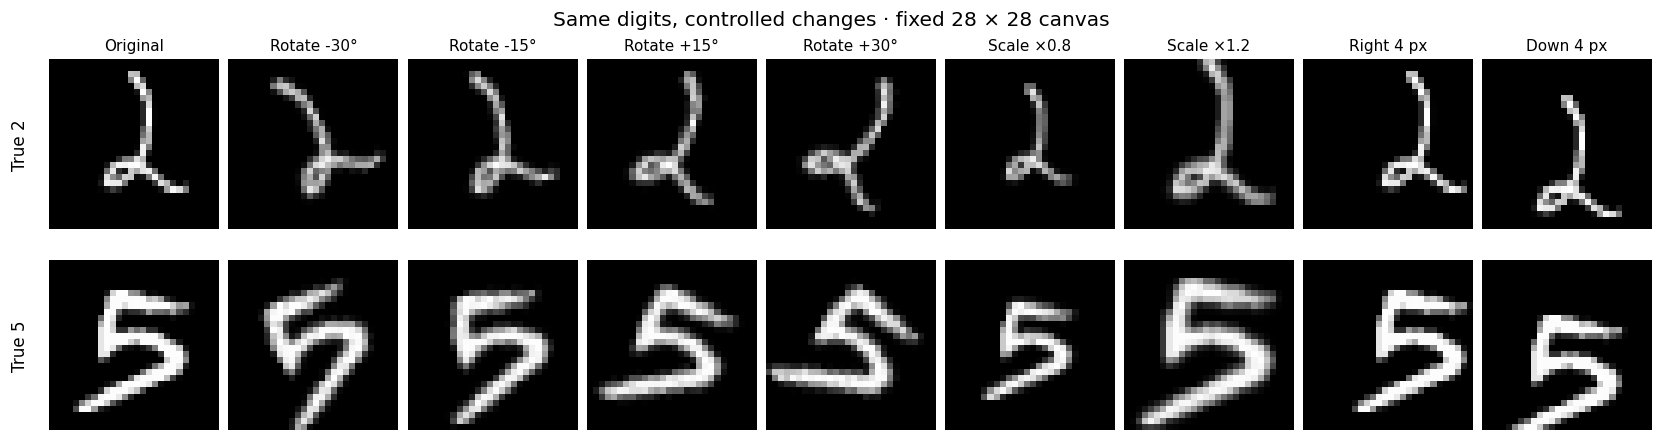

In [50]:
# Read labels directly from the validation subset; no predictions are needed.
preview_targets = mnist.targets[val_indices]
preview_positions = [torch.where(preview_targets == digit)[0][0].item() for digit in (2, 5)]
fig, axes = plt.subplots(2, len(robustness_conditions), figsize=(15, 4), layout="constrained")
for row, position in enumerate(preview_positions):
    image, label = val_set[position]
    for col, condition in enumerate(robustness_conditions):
        transformed = transform_digit(image, condition)
        assert transformed.shape == image.shape and transformed.dtype == torch.float32
        assert 0 <= transformed.min() <= transformed.max() <= 1
        axes[row, col].imshow(transformed[0], cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(condition[0], fontsize=10)
        if col == 0:
            axes[row, col].text(-.12, .5, f"True {label}", transform=axes[row, col].transAxes,
                                ha="right", va="center", rotation=90)
fig.suptitle("Same digits, controlled changes · fixed 28 × 28 canvas")
fig.savefig(artifact_dir / "robustness_inputs.png", dpi=180, bbox_inches="tight")
plt.show()

### 10.2 Measure the change in performance

For each condition, record accuracy and cross-entropy on **every** validation
image. The accuracy change is in **percentage points** relative to the original
images. For example, 98% → 90% means −8 percentage points, not an 8% relative
error reduction.

We also count **new errors** (originally correct, now wrong) and **recovered
errors** (originally wrong, now correct). Some transformations may help some
images while hurting others; the net accuracy change reflects both groups.
The predictions stay aligned because each loader preserves validation order.

In [51]:
# Establish the original-image baseline before testing transformations.
validation_details = evaluate(selected_model, val_loader, collect_predictions=True)
targets = validation_details["targets"]
predictions = validation_details["predictions"]

robustness_state_before = deepcopy(selected_model.state_dict())
baseline_correct = predictions == targets
robustness_details = {"Original": validation_details}
robustness_rows = []
for condition in robustness_conditions:
    name, angle, scale, shift = condition
    if name == "Original":
        metrics = validation_details
    else:
        transformed_set = TransformedValidation(val_set, condition)
        metrics = evaluate(selected_model, make_eval_loader(transformed_set), collect_predictions=True)
    assert metrics["n"] == len(val_set) and torch.equal(metrics["targets"], targets)
    robustness_details[name] = metrics
    now_correct = metrics["predictions"] == targets
    new_errors = (baseline_correct & ~now_correct).sum().item()
    recovered_errors = (~baseline_correct & now_correct).sum().item()
    row = {"condition": name, "angle": angle, "scale": scale,
           "shift_x": shift[0], "shift_y": shift[1], "n": metrics["n"],
           "accuracy": metrics["accuracy"], "loss": metrics["loss"],
           "accuracy_change_pp": 100 * (metrics["accuracy"] - validation_details["accuracy"]),
           "new_errors": new_errors, "recovered_errors": recovered_errors}
    robustness_rows.append(row)
    print(f"{name:12s} | accuracy={row['accuracy']:.2%} | "
          f"change={row['accuracy_change_pp']:+.2f} pp | CE={row['loss']:.4f}", flush=True)
assert all(torch.equal(value, selected_model.state_dict()[key])
           for key, value in robustness_state_before.items())

table = "| Condition | Accuracy | Change (pp) | CE | New errors | Recovered errors |\n"
table += "| --- | ---: | ---: | ---: | ---: | ---: |\n"
for row in robustness_rows:
    table += (f"| {row['condition']} | {row['accuracy']:.2%} | {row['accuracy_change_pp']:+.2f} "
              f"| {row['loss']:.4f} | {row['new_errors']} | {row['recovered_errors']} |\n")
display(Markdown(table))
with (artifact_dir / "robustness_comparison.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(robustness_rows[0]))
    writer.writeheader()
    writer.writerows(robustness_rows)

Original     | accuracy=98.47% | change=+0.00 pp | CE=0.0543
Rotate -30°  | accuracy=83.06% | change=-15.41 pp | CE=0.6433
Rotate -15°  | accuracy=95.77% | change=-2.70 pp | CE=0.1424
Rotate +15°  | accuracy=95.31% | change=-3.16 pp | CE=0.1558
Rotate +30°  | accuracy=75.97% | change=-22.50 pp | CE=0.9020
Scale ×0.8   | accuracy=95.16% | change=-3.31 pp | CE=0.1545
Scale ×1.2   | accuracy=97.02% | change=-1.45 pp | CE=0.1006
Right 4 px   | accuracy=68.18% | change=-30.29 pp | CE=1.2537
Down 4 px    | accuracy=47.12% | change=-51.35 pp | CE=2.7093


| Condition | Accuracy | Change (pp) | CE | New errors | Recovered errors |
| --- | ---: | ---: | ---: | ---: | ---: |
| Original | 98.47% | +0.00 | 0.0543 | 0 | 0 |
| Rotate -30° | 83.06% | -15.41 | 0.6433 | 1586 | 45 |
| Rotate -15° | 95.77% | -2.70 | 0.1424 | 312 | 42 |
| Rotate +15° | 95.31% | -3.16 | 0.1558 | 368 | 52 |
| Rotate +30° | 75.97% | -22.50 | 0.9020 | 2305 | 55 |
| Scale ×0.8 | 95.16% | -3.31 | 0.1545 | 367 | 36 |
| Scale ×1.2 | 97.02% | -1.45 | 0.1006 | 181 | 36 |
| Right 4 px | 68.18% | -30.29 | 1.2537 | 3074 | 45 |
| Down 4 px | 47.12% | -51.35 | 2.7093 | 5174 | 39 |


### 10.3 Find images that became mistakes

Choose the condition with the lowest measured accuracy **only to inspect its
errors**, and show the first six images that were correct originally but wrong
after that change. Each column pairs the original with its transformed copy.
The performance table above reports all preselected conditions, not just this
worst one. If no new errors occurred, the code reports that instead.

Look for readable digits that confuse the model, but also for clipping or
ambiguity introduced by the transformation. These suggest different remedies:
learn more varied examples, or improve how drawings are resized and centered.

Lowest accuracy among these conditions: Down 4 px (47.12%; -51.35 pp)


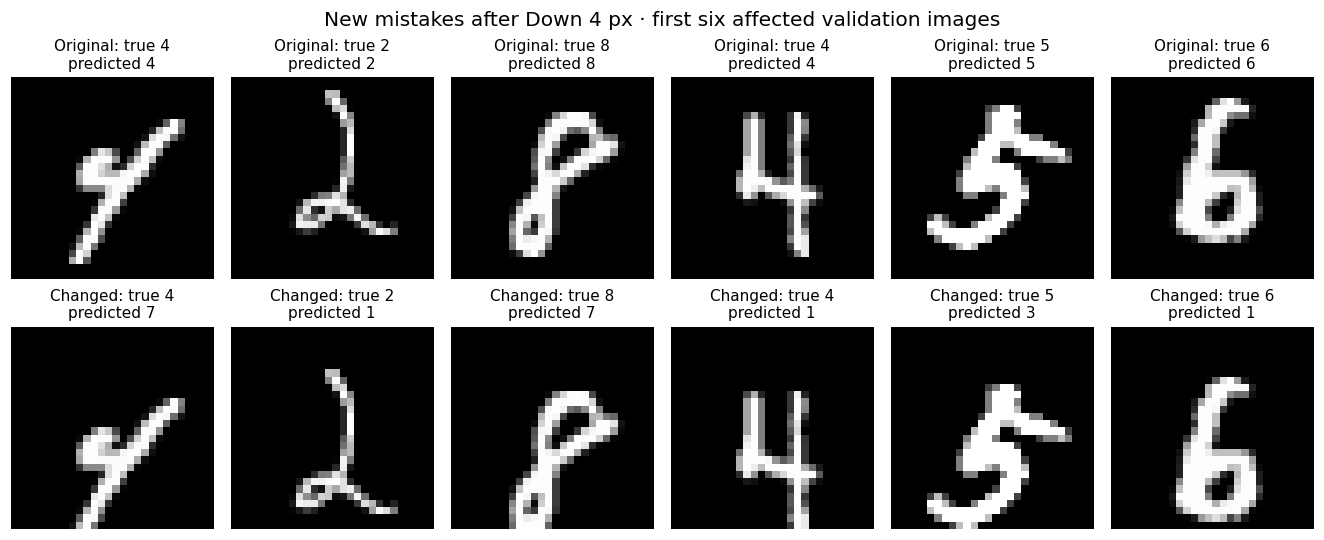

In [ ]:
worst_row = min(robustness_rows[1:], key=lambda row: row["accuracy"])
worst_condition = next(c for c in robustness_conditions if c[0] == worst_row["condition"])
changed_predictions = robustness_details[worst_condition[0]]["predictions"]
new_error_positions = torch.where(baseline_correct & (changed_predictions != targets))[0]
print(f"Lowest accuracy among these conditions: {worst_row['condition']} "
      f"({worst_row['accuracy']:.2%}; {worst_row['accuracy_change_pp']:+.2f} pp)")
if len(new_error_positions) == 0:
    print("No originally correct images became wrong under this condition.")
else:
    show_positions = new_error_positions[:6].tolist()
    fig, axes = plt.subplots(2, len(show_positions), figsize=(12, 4.8),
                             squeeze=False, layout="constrained")
    for col, position in enumerate(show_positions):
        original_image, label = val_set[position]
        changed_image = transform_digit(original_image, worst_condition)
        for row, shown in enumerate((original_image, changed_image)):
            axes[row, col].imshow(shown[0], cmap="gray", vmin=0, vmax=1)
            axes[row, col].axis("off")
        axes[0, col].set_title(f"Original: true {label}\npredicted {predictions[position].item()}", fontsize=10)
        axes[1, col].set_title(f"Changed: true {label}\npredicted {changed_predictions[position].item()}", fontsize=10)
    fig.suptitle(f"New mistakes after {worst_condition[0]} · first six affected validation images")
    fig.savefig(artifact_dir / "robustness_new_errors.png", dpi=180, bbox_inches="tight")
    plt.show()

## 11. Save the evidence and restore the selected model

Weights alone do not describe the whole experiment. We also save settings,
split indices, software versions, learning histories, selected epochs, and
validation metrics. The summary records the small-data experiment separately.
The model-comparison CSV contains one row per model. The robustness CSV
and report also record the exact transformations and their measured results.

Reference: [PyTorch saving and loading models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).

In [ ]:
report = {
    "config": config, "training_images": len(train_set), "validation_images": len(val_set),
    "split_file": "split.json", "preprocessing": "ToTensor: grayscale 1x28x28 in [0,1]",
    "selection_rule": "minimum validation cross-entropy",
    "versions": {"python": platform.python_version(), "torch": str(torch.__version__),
                 "torchvision": str(torchvision.__version__), "numpy": str(np.__version__)},
    "device": str(device), "threads": torch.get_num_threads(),
    "comparison": comparison, "selected_model": selected_name,
    "relative_error_reduction_B_vs_A": relative_error_reduction,
    "robustness_diagnostic": {
        "model": selected_name, "checkpoint_epoch": results[selected_name]["best_epoch"],
        "source": "same validation indices as the original evaluation",
        "interpolation": "bilinear", "fill": 0, "center": "image center",
        "original_resampled": False, "conditions": robustness_rows,
    },
    "official_test_evaluated": False,
}
(artifact_dir / "report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
with (artifact_dir / "model_comparison.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(comparison[0]))
    writer.writeheader()
    writer.writerows(comparison)

checkpoint = torch.load(results[selected_name]["checkpoint"], map_location=device, weights_only=True)
restored_model = model_classes[selected_name]().to(device)
assert checkpoint["architecture"] == type(restored_model).__name__
restored_model.load_state_dict(checkpoint["state_dict"])
restored_model.eval()
fixed_images, _ = next(iter(val_loader))
with torch.no_grad():
    reference_logits = selected_model(fixed_images[:16].to(device))
    restored_logits = restored_model(fixed_images[:16].to(device))
torch.testing.assert_close(restored_logits, reference_logits, rtol=0, atol=0)
print("Restored model reproduces the selected model's logits exactly on 16 validation images.")
print("Selected checkpoint:", results[select ed_name]["checkpoint"])
print("Report:", artifact_dir / "report.json")

Restored model reproduces the selected model's logits exactly on 16 validation images.
Selected checkpoint: /Users/ctx/Desktop/IC/IC4/Machine Learning for Imaging/mli-tutorials/number_classifier/artifacts/tutorial_2/full/B_best.pt
Report: /Users/ctx/Desktop/IC/IC4/Machine Learning for Imaging/mli-tutorials/number_classifier/artifacts/tutorial_2/full/report.json


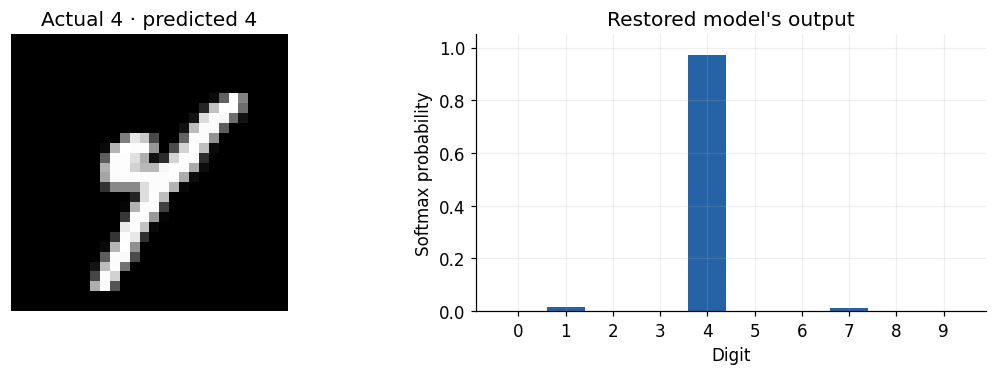

In [ ]:
single_image, single_label = val_set[0]
with torch.no_grad():
    single_logits = restored_model(single_image.unsqueeze(0).to(device))
    single_probabilities = single_logits.softmax(dim=1)[0].cpu()
single_prediction = single_probabilities.argmax().item()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
axes[0].imshow(single_image[0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Actual {single_label} · predicted {single_prediction}")
axes[0].axis("off")
axes[1].bar(range(10), single_probabilities.numpy(), color=TRAIN_COLOR)
axes[1].set(xticks=range(10), ylim=(0, 1.05), xlabel="Digit", ylabel="Softmax probability",
            title="Restored model's output")
plt.show()